In [1]:

# =====================================================================
# EXPERIMENT 04 — PSEUDO-LABEL RELIABILITY ANALYSIS
# Cityscapes -> Foggy Cityscapes
#
# Model: Adaptive Teacher, 5000 iterations
# Evaluation: 3 fog densities, 500 images each
#
# Metrics:
#   - Pseudo-label precision / recall / F1
#   - True positives, false positives, false negatives
#   - Mean confidence and matched-box IoU
#   - Per-class reliability
#   - Confidence threshold sensitivity
#
# IMPORTANT:
# Run in a fresh Jupyter kernel.
# =====================================================================

import os
import sys
import re
import json
import copy
import gc
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from tqdm.auto import tqdm

# ---------------------------------------------------------------------
# 1. ENVIRONMENT
# ---------------------------------------------------------------------

ROOT = Path("/workspace")
BASE = ROOT / "experiments/cityscapes_to_foggy"
DATA_ROOT = ROOT / "datasets"

REPO = ROOT / "adaptive_teacher_recovered/adaptive_teacher"
COMPAT = BASE / "source_only/pilot_1000_v1/python_compat"

TEACHER_DIR = (
    BASE / "adaptive_teacher/pilot_5000_warmstart_v2"
)

TEACHER_CONFIG = (
    TEACHER_DIR / "adaptive_teacher_5000.yaml"
)

TEACHER_CHECKPOINT = TEACHER_DIR / "model_final.pth"

OUTPUT_DIR = (
    BASE / "pseudo_label_analysis/v1"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

os.environ["DETECTRON2_DATASETS"] = str(DATA_ROOT)

for path in [str(COMPAT), str(REPO)]:
    if path not in sys.path:
        sys.path.insert(0, path)

assert TEACHER_CONFIG.is_file(), TEACHER_CONFIG
assert TEACHER_CHECKPOINT.is_file(), TEACHER_CHECKPOINT
assert torch.cuda.is_available(), "CUDA GPU required."

DEVICE = "cuda"

print("=" * 70)
print("EXPERIMENT 04 — PSEUDO-LABEL RELIABILITY")
print("=" * 70)
print("GPU:", torch.cuda.get_device_name(0))
print("Checkpoint:", TEACHER_CHECKPOINT)
print("Output:", OUTPUT_DIR)

# ---------------------------------------------------------------------
# 2. DETECTRON2 + ADAPTIVE TEACHER REGISTRATION
# ---------------------------------------------------------------------

from detectron2.config import get_cfg
from detectron2.data import (
    DatasetCatalog,
    MetadataCatalog,
    build_detection_test_loader,
)
from detectron2.data.datasets.builtin import register_all_cityscapes
from detectron2.modeling import build_model
from detectron2.modeling.backbone import BACKBONE_REGISTRY
from detectron2.modeling.meta_arch.build import META_ARCH_REGISTRY
from detectron2.modeling.proposal_generator.build import (
    PROPOSAL_GENERATOR_REGISTRY,
)
from detectron2.modeling.roi_heads import ROI_HEADS_REGISTRY
from detectron2.structures import Boxes, pairwise_iou

from adapteacher.config import add_ateacher_config

import adapteacher.modeling
import prod_lib.modeling

# Load configuration.
cfg = get_cfg()
add_ateacher_config(cfg)
cfg.merge_from_file(str(TEACHER_CONFIG))

cfg.defrost()
cfg.MODEL.DEVICE = DEVICE
cfg.DATALOADER.NUM_WORKERS = 0

# Preserve low-confidence predictions for threshold analysis.
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.05

cfg.freeze()


def ensure_registration(name, registry):

    if name in registry._obj_map:
        return

    candidates = []

    for file in REPO.rglob("*.py"):
        try:
            content = file.read_text(errors="replace")
        except OSError:
            continue

        if re.search(
            rf"\b(?:def|class)\s+{re.escape(name)}\b",
            content
        ):
            candidates.append(file)

    if not candidates:
        raise RuntimeError(
            f"No implementation found for {name}"
        )

    for file in candidates:

        if name in registry._obj_map:
            break

        module = ".".join(
            file.relative_to(REPO).with_suffix("").parts
        )

        if module not in sys.modules:
            importlib.import_module(module)

    if name not in registry._obj_map:
        raise RuntimeError(
            f"Unable to register {name}"
        )


ensure_registration(
    cfg.MODEL.META_ARCHITECTURE,
    META_ARCH_REGISTRY
)

ensure_registration(
    cfg.MODEL.BACKBONE.NAME,
    BACKBONE_REGISTRY
)

ensure_registration(
    cfg.MODEL.PROPOSAL_GENERATOR.NAME,
    PROPOSAL_GENERATOR_REGISTRY
)

ensure_registration(
    cfg.MODEL.ROI_HEADS.NAME,
    ROI_HEADS_REGISTRY
)

print("\nModel registrations verified.")

# ---------------------------------------------------------------------
# 3. DATASET REGISTRATION
# ---------------------------------------------------------------------

FOG_LEVELS = {
    "light": "0.005",
    "medium": "0.01",
    "strong": "0.02",
}

THRESHOLDS = [0.50, 0.70, 0.80, 0.90]

IOU_THRESHOLD = 0.50

CLASSES = [
    "person", "rider", "car", "truck",
    "bus", "train", "motorcycle", "bicycle"
]

SOURCE_DATASET = "cityscapes_fine_instance_seg_val"

if SOURCE_DATASET not in DatasetCatalog.list():
    register_all_cityscapes(str(DATA_ROOT))

source_records = DatasetCatalog.get(SOURCE_DATASET)

assert len(source_records) == 500


def canonical_name(filename):
    name = Path(filename).stem
    name = re.sub(r"_foggy_beta_[0-9.]+$", "", name)
    name = re.sub(r"_leftImg8bit$", "", name)
    return name


lookup = {
    canonical_name(record["file_name"]): record
    for record in source_records
}

assert len(lookup) == 500

FOG_DATASETS = {}

for level, beta in FOG_LEVELS.items():

    dataset_name = f"cityscapes_foggy_val_{level}"

    images = sorted(
        (
            DATA_ROOT / "cityscapes_foggy/leftImg8bit/val"
        ).rglob(
            f"*_leftImg8bit_foggy_beta_{beta}.png"
        )
    )

    assert len(images) == 500, (
        f"{level}: expected 500 images, got {len(images)}"
    )

    records = []

    for image_path in images:

        key = canonical_name(image_path)

        if key not in lookup:
            raise KeyError(
                f"Missing annotation for {image_path}"
            )

        record = copy.deepcopy(lookup[key])
        record["file_name"] = str(image_path)

        records.append(record)

    if dataset_name in DatasetCatalog.list():
        DatasetCatalog.remove(dataset_name)

    DatasetCatalog.register(
        dataset_name,
        lambda records=records: copy.deepcopy(records)
    )

    MetadataCatalog.get(dataset_name).set(
        thing_classes=list(
            MetadataCatalog.get(
                SOURCE_DATASET
            ).thing_classes
        ),
        evaluator_type="coco",
    )

    FOG_DATASETS[level] = dataset_name

    print(
        f"Registered {dataset_name}: "
        f"{len(records)} images"
    )

# ---------------------------------------------------------------------
# 4. LOAD TEACHER MODEL
# ---------------------------------------------------------------------

checkpoint = torch.load(
    str(TEACHER_CHECKPOINT),
    map_location="cpu",
    weights_only=False
)

state = checkpoint.get("model", checkpoint)

teacher_weights = {
    k[len("modelTeacher."):]: v
    for k, v in state.items()
    if k.startswith("modelTeacher.")
}

assert teacher_weights, "Teacher weights not found."

model = build_model(cfg)

expected = model.state_dict()

missing = set(expected) - set(teacher_weights)
unexpected = set(teacher_weights) - set(expected)

shape_errors = [
    k for k in expected
    if k in teacher_weights
    and expected[k].shape != teacher_weights[k].shape
]

print("\nCheckpoint validation:")
print("Missing:", len(missing))
print("Unexpected:", len(unexpected))
print("Shape errors:", len(shape_errors))

assert not missing and not unexpected and not shape_errors, (
    "Teacher checkpoint incompatible with model."
)

model.load_state_dict(teacher_weights, strict=True)
model.eval()

del checkpoint, state, teacher_weights
gc.collect()

print("Teacher model loaded successfully.")

# ---------------------------------------------------------------------
# 5. PREDICTION MATCHING
# ---------------------------------------------------------------------

def match_predictions(
    pred_boxes,
    pred_classes,
    pred_scores,
    gt_boxes,
    gt_classes,
    confidence_threshold,
    iou_threshold=0.50
):
    """
    Greedy one-to-one matching:
      - Predictions sorted by confidence descending
      - Match only same-class GT boxes
      - IoU >= threshold
      - Each GT can match at most once

    Returns:
      TP, FP, FN, matched IoUs, TP scores, FP scores
    """

    selected = np.where(
        pred_scores >= confidence_threshold
    )[0]

    selected = selected[
        np.argsort(-pred_scores[selected])
    ]

    gt_used = np.zeros(
        len(gt_boxes), dtype=bool
    )

    tp = 0
    fp = 0

    matched_ious = []
    tp_scores = []
    fp_scores = []

    if len(selected) and len(gt_boxes):

        iou_matrix = pairwise_iou(
            Boxes(torch.as_tensor(
                pred_boxes[selected],
                dtype=torch.float32
            )),
            Boxes(torch.as_tensor(
                gt_boxes,
                dtype=torch.float32
            ))
        ).numpy()

    else:
        iou_matrix = np.zeros(
            (len(selected), len(gt_boxes))
        )

    for row_idx, pred_idx in enumerate(selected):

        valid = [
            j for j in range(len(gt_boxes))
            if (
                not gt_used[j]
                and pred_classes[pred_idx] == gt_classes[j]
            )
        ]

        if valid:
            best_gt = max(
                valid,
                key=lambda j: iou_matrix[row_idx, j]
            )

            best_iou = iou_matrix[
                row_idx, best_gt
            ]

            if best_iou >= iou_threshold:
                tp += 1
                gt_used[best_gt] = True
                matched_ious.append(float(best_iou))
                tp_scores.append(
                    float(pred_scores[pred_idx])
                )
                continue

        fp += 1
        fp_scores.append(
            float(pred_scores[pred_idx])
        )

    fn = int((~gt_used).sum())

    return {
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "matched_ious": matched_ious,
        "tp_scores": tp_scores,
        "fp_scores": fp_scores,
    }


# ---------------------------------------------------------------------
# 6. RUN TEACHER INFERENCE
# ---------------------------------------------------------------------

all_rows = []
all_class_rows = []
all_confidence_rows = []

for level, beta in FOG_LEVELS.items():

    dataset_name = FOG_DATASETS[level]

    records = DatasetCatalog.get(dataset_name)

    gt_lookup = {
        record["image_id"]: record
        for record in records
    }

    loader = build_detection_test_loader(
        cfg, dataset_name
    )

    predictions = []

    print("\n" + "=" * 70)
    print(
        f"EVALUATING PSEUDO-LABELS — {level.upper()} FOG"
    )
    print("=" * 70)

    with torch.inference_mode():

        for batch in tqdm(loader, desc=level):

            outputs = model(batch)

            for input_item, output_item in zip(
                batch, outputs
            ):

                instances = output_item["instances"].to("cpu")

                predictions.append({
                    "image_id": input_item["image_id"],
                    "boxes": (
                        instances.pred_boxes.tensor.numpy()
                    ),
                    "classes": (
                        instances.pred_classes.numpy()
                    ),
                    "scores": (
                        instances.scores.numpy()
                    )
                })

    assert len(predictions) == 500, (
        f"{level}: expected 500 predictions"
    )

    # Evaluate all confidence thresholds.
    for threshold in THRESHOLDS:

        total_tp = 0
        total_fp = 0
        total_fn = 0

        matched_ious = []
        tp_scores = []
        fp_scores = []

        per_class = {
            cls_id: {
                "tp": 0,
                "fp": 0,
                "fn": 0
            }
            for cls_id in range(len(CLASSES))
        }

        for pred in predictions:

            record = gt_lookup[pred["image_id"]]

            annotations = record.get(
                "annotations", []
            )

            gt_boxes = np.array(
                [ann["bbox"] for ann in annotations],
                dtype=np.float32
            ).reshape(-1, 4)

            gt_classes = np.array(
                [ann["category_id"] for ann in annotations],
                dtype=np.int64
            )

            result = match_predictions(
                pred["boxes"],
                pred["classes"],
                pred["scores"],
                gt_boxes,
                gt_classes,
                threshold,
                IOU_THRESHOLD
            )

            total_tp += result["tp"]
            total_fp += result["fp"]
            total_fn += result["fn"]

            matched_ious.extend(
                result["matched_ious"]
            )

            tp_scores.extend(
                result["tp_scores"]
            )

            fp_scores.extend(
                result["fp_scores"]
            )

            # Per-class matching.
            for cls_id in range(len(CLASSES)):

                pred_mask = (
                    pred["classes"] == cls_id
                )

                gt_mask = (
                    gt_classes == cls_id
                )

                class_result = match_predictions(
                    pred["boxes"][pred_mask],
                    pred["classes"][pred_mask],
                    pred["scores"][pred_mask],
                    gt_boxes[gt_mask],
                    gt_classes[gt_mask],
                    threshold,
                    IOU_THRESHOLD
                )

                per_class[cls_id]["tp"] += (
                    class_result["tp"]
                )
                per_class[cls_id]["fp"] += (
                    class_result["fp"]
                )
                per_class[cls_id]["fn"] += (
                    class_result["fn"]
                )

        precision = (
            total_tp / (total_tp + total_fp)
            if total_tp + total_fp else 0
        )

        recall = (
            total_tp / (total_tp + total_fn)
            if total_tp + total_fn else 0
        )

        f1 = (
            2 * precision * recall /
            (precision + recall)
            if precision + recall else 0
        )

        all_rows.append({
            "fog_density": level,
            "beta": float(beta),
            "confidence_threshold": threshold,
            "iou_threshold": IOU_THRESHOLD,
            "tp": total_tp,
            "fp": total_fp,
            "fn": total_fn,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "mean_matched_iou": (
                np.mean(matched_ious)
                if matched_ious else np.nan
            ),
            "mean_tp_confidence": (
                np.mean(tp_scores)
                if tp_scores else np.nan
            ),
            "mean_fp_confidence": (
                np.mean(fp_scores)
                if fp_scores else np.nan
            ),
        })

        for cls_id, cls_name in enumerate(CLASSES):

            counts = per_class[cls_id]

            tp = counts["tp"]
            fp = counts["fp"]
            fn = counts["fn"]

            all_class_rows.append({
                "fog_density": level,
                "confidence_threshold": threshold,
                "class": cls_name,
                "tp": tp,
                "fp": fp,
                "fn": fn,
                "precision": (
                    tp / (tp + fp)
                    if tp + fp else 0
                ),
                "recall": (
                    tp / (tp + fn)
                    if tp + fn else 0
                )
            })

        all_confidence_rows.extend(
            [
                {
                    "fog_density": level,
                    "confidence_threshold": threshold,
                    "match_type": "true_positive",
                    "confidence": score
                }
                for score in tp_scores
            ]
        )

        all_confidence_rows.extend(
            [
                {
                    "fog_density": level,
                    "confidence_threshold": threshold,
                    "match_type": "false_positive",
                    "confidence": score
                }
                for score in fp_scores
            ]
        )

        print(
            f"Threshold={threshold:.2f} | "
            f"Precision={precision:.3f} | "
            f"Recall={recall:.3f} | "
            f"F1={f1:.3f}"
        )

    # Save predictions for future research analysis.
    with open(
        OUTPUT_DIR / f"predictions_{level}.json",
        "w"
    ) as file:

        json.dump(
            [
                {
                    "image_id": p["image_id"],
                    "boxes": p["boxes"].tolist(),
                    "classes": p["classes"].tolist(),
                    "scores": p["scores"].tolist()
                }
                for p in predictions
            ],
            file
        )

    del predictions
    gc.collect()

# ---------------------------------------------------------------------
# 7. EXPORT RESULTS
# ---------------------------------------------------------------------

reliability_df = pd.DataFrame(all_rows)
per_class_df = pd.DataFrame(all_class_rows)
confidence_df = pd.DataFrame(all_confidence_rows)

reliability_df.to_csv(
    OUTPUT_DIR / "pseudo_label_reliability.csv",
    index=False
)

per_class_df.to_csv(
    OUTPUT_DIR / "pseudo_label_per_class.csv",
    index=False
)

confidence_df.to_csv(
    OUTPUT_DIR / "pseudo_label_confidence.csv",
    index=False
)

print("\n" + "=" * 70)
print("EXPERIMENT 04 INFERENCE COMPLETE")
print("=" * 70)

display(reliability_df.round(4))

print("\nResults saved to:", OUTPUT_DIR)


EXPERIMENT 04 — PSEUDO-LABEL RELIABILITY
GPU: NVIDIA RTX PRO 4000 Blackwell
Checkpoint: /workspace/experiments/cityscapes_to_foggy/adaptive_teacher/pilot_5000_warmstart_v2/model_final.pth
Output: /workspace/experiments/cityscapes_to_foggy/pseudo_label_analysis/v1

Model registrations verified.
Registered cityscapes_foggy_val_light: 500 images
Registered cityscapes_foggy_val_medium: 500 images
Registered cityscapes_foggy_val_strong: 500 images

Checkpoint validation:
Missing: 0
Unexpected: 0
Shape errors: 0
Teacher model loaded successfully.

EVALUATING PSEUDO-LABELS — LIGHT FOG


light:   0%|          | 0/500 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4322.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


Threshold=0.50 | Precision=0.422 | Recall=0.462 | F1=0.441
Threshold=0.70 | Precision=0.601 | Recall=0.407 | F1=0.485
Threshold=0.80 | Precision=0.718 | Recall=0.370 | F1=0.488
Threshold=0.90 | Precision=0.852 | Recall=0.306 | F1=0.450

EVALUATING PSEUDO-LABELS — MEDIUM FOG


medium:   0%|          | 0/500 [00:00<?, ?it/s]

Threshold=0.50 | Precision=0.440 | Recall=0.445 | F1=0.442
Threshold=0.70 | Precision=0.617 | Recall=0.395 | F1=0.482
Threshold=0.80 | Precision=0.733 | Recall=0.358 | F1=0.481
Threshold=0.90 | Precision=0.860 | Recall=0.301 | F1=0.446

EVALUATING PSEUDO-LABELS — STRONG FOG


strong:   0%|          | 0/500 [00:00<?, ?it/s]

Threshold=0.50 | Precision=0.468 | Recall=0.405 | F1=0.434
Threshold=0.70 | Precision=0.638 | Recall=0.358 | F1=0.459
Threshold=0.80 | Precision=0.746 | Recall=0.328 | F1=0.456
Threshold=0.90 | Precision=0.857 | Recall=0.279 | F1=0.421

EXPERIMENT 04 INFERENCE COMPLETE


,fog_density,beta,confidence_threshold,iou_threshold,tp,fp,fn,precision,recall,f1,mean_matched_iou,mean_tp_confidence,mean_fp_confidence
0,light,0.005,0.5,0.5,4925,6754,5733,0.4217,0.4621,0.4410,0.7446,0.8973,0.6889
1,light,0.005,0.7,0.5,4336,2879,6322,0.6010,0.4068,0.4852,0.7595,0.9368,0.8188
2,light,0.005,0.8,0.5,3939,1548,6719,0.7179,0.3696,0.4880,0.7704,0.9556,0.8806
3,light,0.005,0.9,0.5,3262,568,7396,0.8517,0.3061,0.4503,0.7926,0.9766,0.9393
4,medium,0.010,0.5,0.5,4743,6044,5915,0.4397,0.4450,0.4423,0.7457,0.9013,0.6903
5,medium,0.010,0.7,0.5,4210,2615,6448,0.6168,0.3950,0.4816,0.7595,0.9385,0.8194
6,medium,0.010,0.8,0.5,3811,1387,6847,0.7332,0.3576,0.4807,0.7710,0.9578,0.8831
7,medium,0.010,0.9,0.5,3204,520,7454,0.8604,0.3006,0.4456,0.7915,0.9770,0.9410
8,strong,0.020,0.5,0.5,4321,4920,6337,0.4676,0.4054,0.4343,0.7506,0.9029,0.6951
9,strong,0.020,0.7,0.5,3815,2168,6843,0.6376,0.3579,0.4585,0.7651,0.9422,0.8241



Results saved to: /workspace/experiments/cityscapes_to_foggy/pseudo_label_analysis/v1


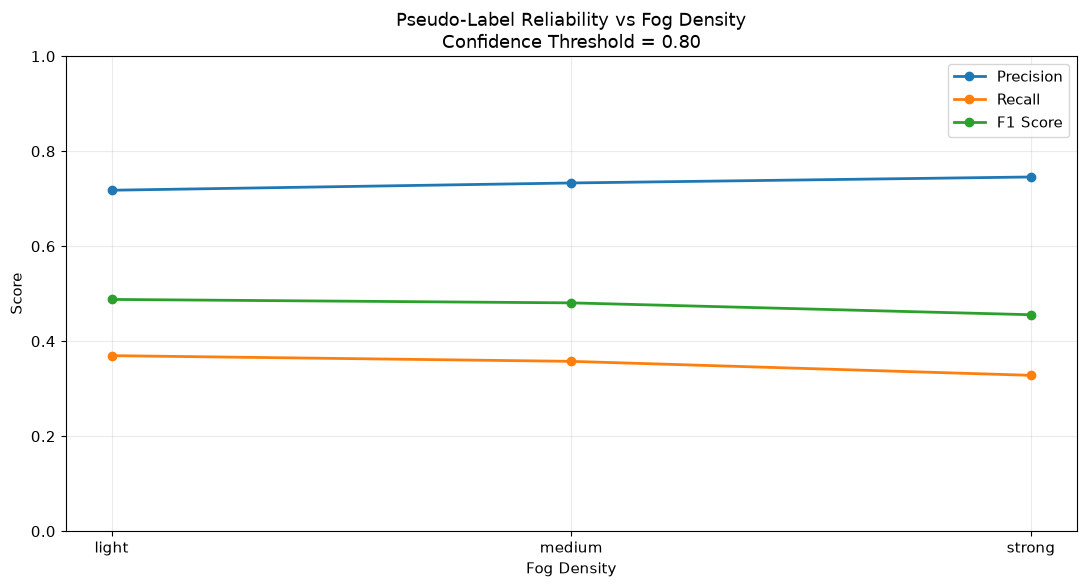

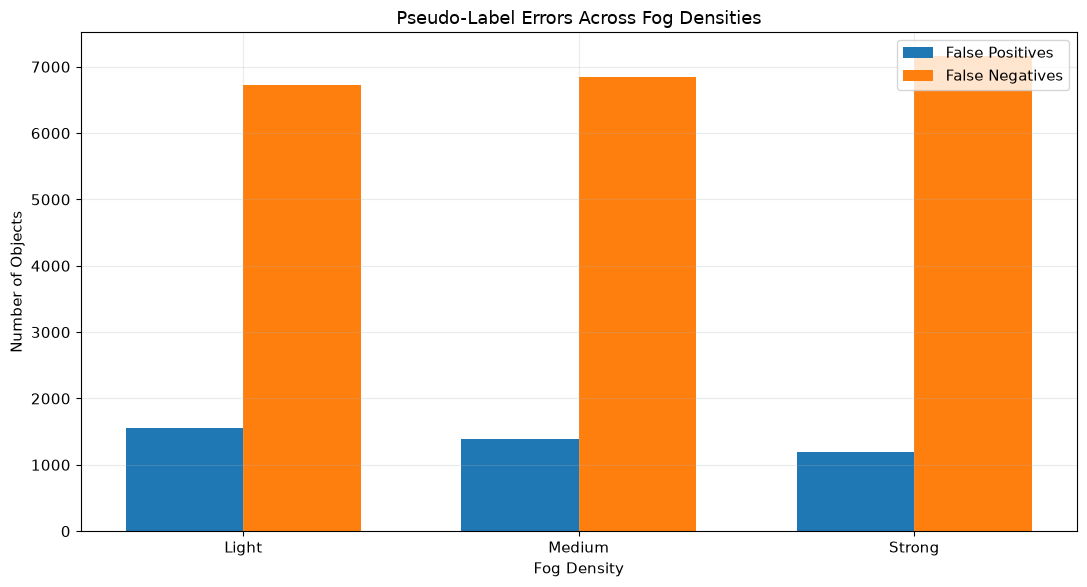

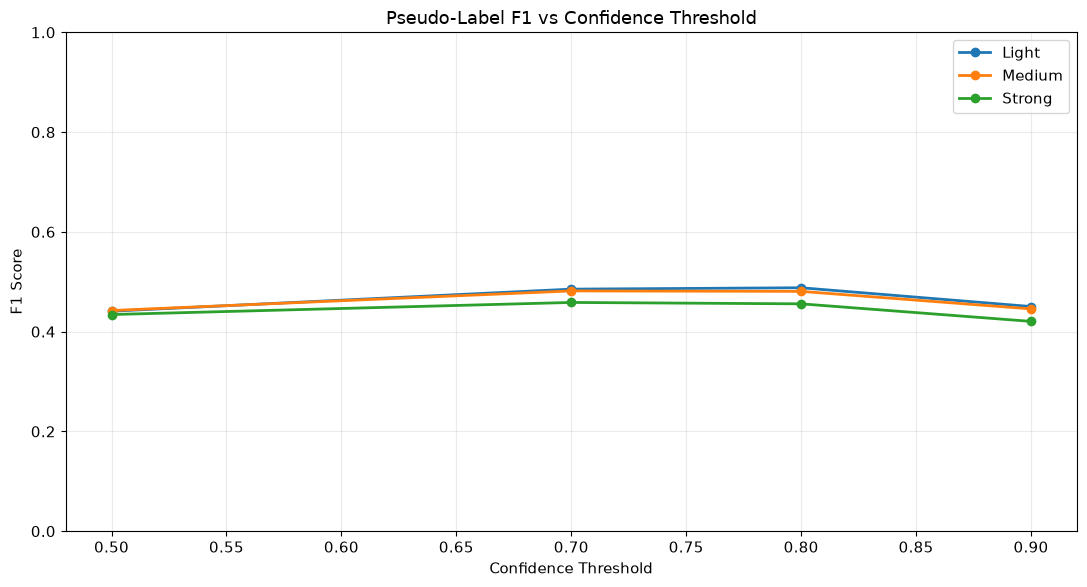

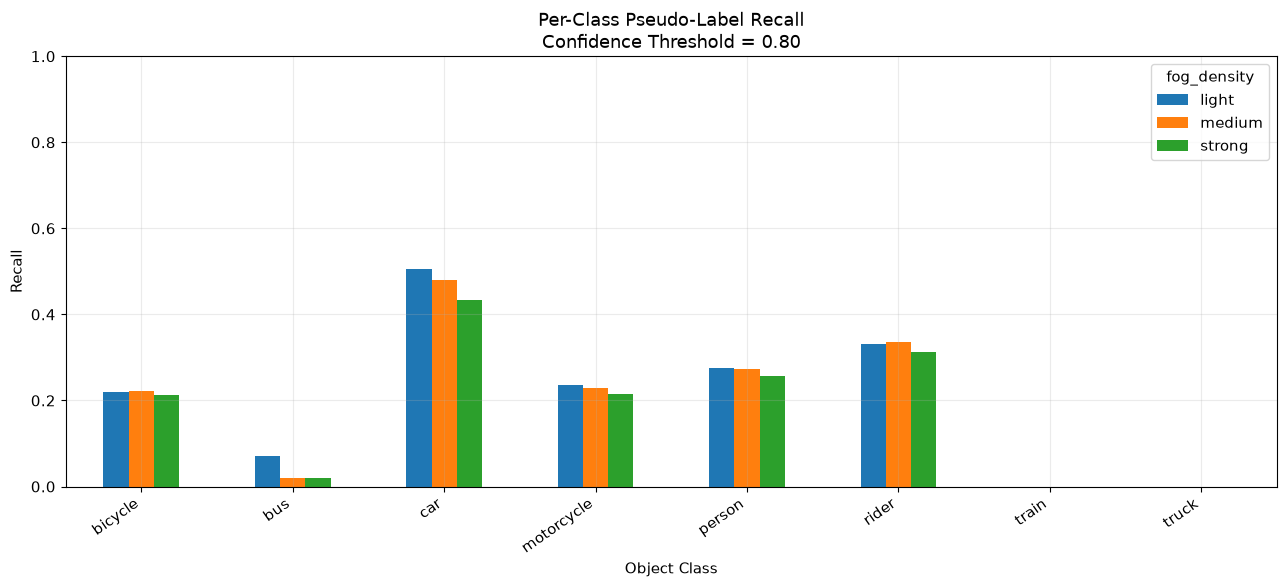


EXPERIMENT 04 COMPLETE

Reliability at confidence threshold 0.80:


,fog_density,tp,fp,fn,precision,recall,f1,mean_matched_iou
2,light,3939,1548,6719,0.7179,0.3696,0.4880,0.7704
6,medium,3811,1387,6847,0.7332,0.3576,0.4807,0.7710
10,strong,3497,1192,7161,0.7458,0.3281,0.4557,0.7747



Results: /workspace/experiments/cityscapes_to_foggy/pseudo_label_analysis/v1
Visualizations: /workspace/experiments/cityscapes_to_foggy/pseudo_label_analysis/v1/visualizations


In [2]:

# =====================================================================
# EXPERIMENT 04 — PSEUDO-LABEL ANALYSIS VISUALIZATIONS
# =====================================================================

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUTPUT_DIR = Path(
    "/workspace/experiments/cityscapes_to_foggy/"
    "pseudo_label_analysis/v1"
)

VIS_DIR = OUTPUT_DIR / "visualizations"
VIS_DIR.mkdir(parents=True, exist_ok=True)

reliability_df = pd.read_csv(
    OUTPUT_DIR / "pseudo_label_reliability.csv"
)

per_class_df = pd.read_csv(
    OUTPUT_DIR / "pseudo_label_per_class.csv"
)

confidence_df = pd.read_csv(
    OUTPUT_DIR / "pseudo_label_confidence.csv"
)

FOG_ORDER = ["light", "medium", "strong"]
THRESHOLDS = [0.50, 0.70, 0.80, 0.90]

plt.rcParams.update({
    "figure.figsize": (11, 6),
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

# ---------------------------------------------------------------------
# 1. PRECISION / RECALL / F1 ACROSS FOG LEVELS
# ---------------------------------------------------------------------

subset = reliability_df[
    np.isclose(
        reliability_df["confidence_threshold"], 0.80
    )
].copy()

subset["fog_density"] = pd.Categorical(
    subset["fog_density"],
    categories=FOG_ORDER,
    ordered=True
)

subset = subset.sort_values("fog_density")

fig, ax = plt.subplots()

for metric, label in [
    ("precision", "Precision"),
    ("recall", "Recall"),
    ("f1", "F1 Score")
]:
    ax.plot(
        subset["fog_density"].astype(str),
        subset[metric],
        marker="o",
        linewidth=2,
        label=label
    )

ax.set(
    title="Pseudo-Label Reliability vs Fog Density\n"
          "Confidence Threshold = 0.80",
    xlabel="Fog Density",
    ylabel="Score"
)

ax.set_ylim(0, 1)
ax.legend()

plt.tight_layout()
plt.savefig(
    VIS_DIR / "01_precision_recall_f1.png",
    dpi=200
)
plt.show()

# ---------------------------------------------------------------------
# 2. FALSE POSITIVES AND FALSE NEGATIVES
# ---------------------------------------------------------------------

x = np.arange(len(FOG_ORDER))
width = 0.35

fig, ax = plt.subplots()

bars_fp = ax.bar(
    x - width / 2,
    subset["fp"],
    width,
    label="False Positives"
)

bars_fn = ax.bar(
    x + width / 2,
    subset["fn"],
    width,
    label="False Negatives"
)

ax.set_xticks(x)
ax.set_xticklabels(
    ["Light", "Medium", "Strong"]
)

ax.set(
    title="Pseudo-Label Errors Across Fog Densities",
    xlabel="Fog Density",
    ylabel="Number of Objects"
)

ax.legend()

plt.tight_layout()
plt.savefig(
    VIS_DIR / "02_false_positives_negatives.png",
    dpi=200
)
plt.show()

# ---------------------------------------------------------------------
# 3. CONFIDENCE THRESHOLD SENSITIVITY
# ---------------------------------------------------------------------

fig, ax = plt.subplots()

for level in FOG_ORDER:

    data = reliability_df[
        reliability_df["fog_density"] == level
    ].sort_values("confidence_threshold")

    ax.plot(
        data["confidence_threshold"],
        data["f1"],
        marker="o",
        linewidth=2,
        label=level.title()
    )

ax.set(
    title="Pseudo-Label F1 vs Confidence Threshold",
    xlabel="Confidence Threshold",
    ylabel="F1 Score"
)

ax.set_ylim(0, 1)
ax.legend()

plt.tight_layout()
plt.savefig(
    VIS_DIR / "03_threshold_sensitivity.png",
    dpi=200
)
plt.show()

# ---------------------------------------------------------------------
# 4. PER-CLASS PSEUDO-LABEL RECALL
# ---------------------------------------------------------------------

class_subset = per_class_df[
    np.isclose(
        per_class_df["confidence_threshold"], 0.80
    )
]

pivot = class_subset.pivot(
    index="class",
    columns="fog_density",
    values="recall"
)

pivot = pivot.reindex(
    columns=FOG_ORDER
)

ax = pivot.plot(
    kind="bar",
    figsize=(13, 6)
)

ax.set(
    title="Per-Class Pseudo-Label Recall\n"
          "Confidence Threshold = 0.80",
    xlabel="Object Class",
    ylabel="Recall"
)

ax.set_ylim(0, 1)

plt.xticks(rotation=35, ha="right")
plt.tight_layout()

plt.savefig(
    VIS_DIR / "04_per_class_recall.png",
    dpi=200
)
plt.show()

# ---------------------------------------------------------------------
# 5. RESEARCH SUMMARY
# ---------------------------------------------------------------------

summary = {
    "experiment": "Experiment 04",
    "title": "Pseudo-Label Reliability Analysis",
    "model": "Adaptive Teacher",
    "checkpoint": (
        "/workspace/experiments/cityscapes_to_foggy/"
        "adaptive_teacher/pilot_5000_warmstart_v2/model_final.pth"
    ),
    "fog_levels": {
        "light": 0.005,
        "medium": 0.01,
        "strong": 0.02
    },
    "confidence_thresholds": THRESHOLDS,
    "matching_iou": 0.50,
    "results": reliability_df.to_dict(
        orient="records"
    )
}

with open(
    OUTPUT_DIR / "experiment_summary.json",
    "w"
) as file:
    json.dump(summary, file, indent=2)

print("\n" + "=" * 70)
print("EXPERIMENT 04 COMPLETE")
print("=" * 70)

print("\nReliability at confidence threshold 0.80:")

display(
    subset[
        [
            "fog_density",
            "tp",
            "fp",
            "fn",
            "precision",
            "recall",
            "f1",
            "mean_matched_iou"
        ]
    ].round(4)
)

print("\nResults:", OUTPUT_DIR)
print("Visualizations:", VIS_DIR)


PASS: duplicate, class, empty, confidence, box conversion tests
Ground-truth bbox modes: {'0': 31974}
Ground-truth object count per density: {'light': 10658, 'medium': 10658, 'strong': 10658}
PASS: 500 matched image IDs at each fog density
light  threshold=0.50: verified TP/FP/FN=4925/6754/5733; previous=4925/6754/5733
light  threshold=0.70: verified TP/FP/FN=4336/2879/6322; previous=4336/2879/6322
light  threshold=0.80: verified TP/FP/FN=3939/1548/6719; previous=3939/1548/6719
light  threshold=0.90: verified TP/FP/FN=3262/568/7396; previous=3262/568/7396
medium threshold=0.50: verified TP/FP/FN=4743/6044/5915; previous=4743/6044/5915
medium threshold=0.70: verified TP/FP/FN=4210/2615/6448; previous=4210/2615/6448
medium threshold=0.80: verified TP/FP/FN=3811/1387/6847; previous=3811/1387/6847
medium threshold=0.90: verified TP/FP/FN=3204/520/7454; previous=3204/520/7454
strong threshold=0.50: verified TP/FP/FN=4321/4920/6337; previous=4321/4920/6337
strong threshold=0.70: verified TP/

reason,low_confidence_candidate,no_overlapping_candidate,overlapping_duplicate_or_assignment,poor_localization,wrong_class_candidate
fog_density,,,,,
light,1918,868,152,3498,283
medium,1895,1105,150,3427,270
strong,1802,1642,134,3327,256



PER-CLASS RECALL AT THRESHOLD 0.80


fog_density,light,medium,strong,drop_light_to_strong_pp
class,,,,
car,0.5061,0.4810,0.4335,-7.2659
bus,0.0714,0.0204,0.0204,-5.1020
motorcycle,0.2349,0.2282,0.2148,-2.0134
person,0.2747,0.2727,0.2564,-1.8351
rider,0.3315,0.3352,0.3132,-1.8315
bicycle,0.2194,0.2223,0.2129,-0.6475
train,0.0000,0.0000,0.0000,0.0000
truck,0.0000,0.0000,0.0000,0.0000


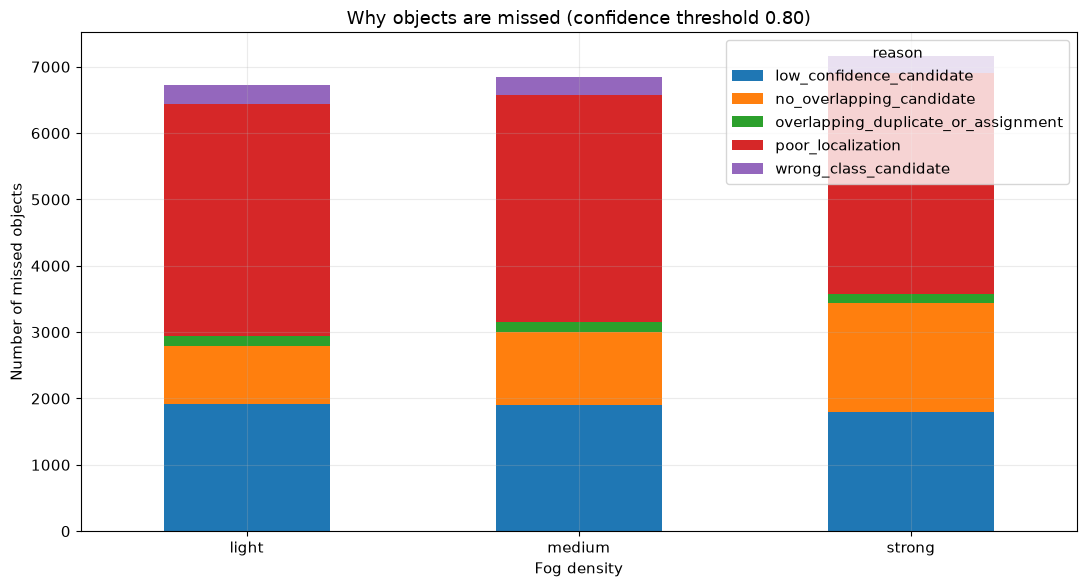


OUTPUT: /workspace/experiments/cityscapes_to_foggy/pseudo_label_analysis/v1/object_analysis_v2
OBJECT ANALYSIS COMPLETE


In [3]:

# =====================================================================
# EXPERIMENT 04 — OBJECT-LEVEL ANALYSIS & MATCHING VERIFICATION
# CELL 3 — NO RETRAINING OR GPU INFERENCE REQUIRED
# =====================================================================

import os, sys, re, json, copy
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("/workspace")
BASE = ROOT / "experiments/cityscapes_to_foggy"
DATA_ROOT = ROOT / "datasets"
PRED_DIR = BASE / "pseudo_label_analysis/v1"
OUT = PRED_DIR / "object_analysis_v2"
OUT.mkdir(parents=True, exist_ok=True)

FOG = {"light": "0.005", "medium": "0.01", "strong": "0.02"}
CLASSES = [
    "person", "rider", "car", "truck",
    "bus", "train", "motorcycle", "bicycle"
]
THRESHOLDS = [0.05, 0.50, 0.70, 0.80, 0.90]
IOU = 0.50

from detectron2.data import DatasetCatalog, MetadataCatalog
from detectron2.data.datasets.builtin import register_all_cityscapes
from detectron2.structures import (
    BoxMode, Boxes, pairwise_iou
)

# ----------------------------------------------------------
# A. INDEPENDENT MATCHING TESTS
# ----------------------------------------------------------

def match(pred_boxes, pred_cls, scores, gt_boxes, gt_cls,
          threshold=0.80, iou_threshold=0.50):

    pred_boxes = np.asarray(pred_boxes, dtype=float).reshape(-1, 4)
    gt_boxes = np.asarray(gt_boxes, dtype=float).reshape(-1, 4)
    pred_cls = np.asarray(pred_cls, dtype=int)
    gt_cls = np.asarray(gt_cls, dtype=int)
    scores = np.asarray(scores, dtype=float)

    selected = np.flatnonzero(scores >= threshold)
    selected = selected[np.argsort(-scores[selected], kind="stable")]

    used = set()
    matches = []
    false_positives = []

    if len(selected) and len(gt_boxes):
        pb = pred_boxes[selected]
        x1 = np.maximum(pb[:, None, 0], gt_boxes[None, :, 0])
        y1 = np.maximum(pb[:, None, 1], gt_boxes[None, :, 1])
        x2 = np.minimum(pb[:, None, 2], gt_boxes[None, :, 2])
        y2 = np.minimum(pb[:, None, 3], gt_boxes[None, :, 3])
        intersection = np.maximum(x2-x1, 0) * np.maximum(y2-y1, 0)
        pa = np.maximum(pb[:,2]-pb[:,0],0) * np.maximum(pb[:,3]-pb[:,1],0)
        ga = np.maximum(gt_boxes[:,2]-gt_boxes[:,0],0) * np.maximum(gt_boxes[:,3]-gt_boxes[:,1],0)
        union = pa[:,None] + ga[None,:] - intersection
        matrix = np.divide(
            intersection, union,
            out=np.zeros_like(intersection),
            where=union > 0
        )
    else:
        matrix = np.zeros((len(selected), len(gt_boxes)))

    for row, pi in enumerate(selected):
        valid = [
            gi for gi in range(len(gt_boxes))
            if gi not in used and pred_cls[pi] == gt_cls[gi]
        ]
        if valid:
            gi = max(valid, key=lambda g: matrix[row, g])
            if matrix[row, gi] >= iou_threshold:
                used.add(gi)
                matches.append((int(pi), int(gi), float(matrix[row,gi])))
                continue
        false_positives.append(int(pi))

    unmatched_gt = sorted(set(range(len(gt_boxes))) - used)

    return {
        "tp": len(matches),
        "fp": len(false_positives),
        "fn": len(unmatched_gt),
        "matches": matches,
        "false_positives": false_positives,
        "unmatched_gt": unmatched_gt,
        "iou_matrix": matrix,
        "selected": selected
    }


def self_test():
    gt = [[0,0,10,10]]
    pb = [[0,0,10,10],[0,0,10,10]]
    r = match(pb,[0,0],[0.9,0.8],gt,[0],0.5)
    assert (r["tp"],r["fp"],r["fn"]) == (1,1,0)

    r = match(pb,[1,1],[0.9,0.8],gt,[0],0.5)
    assert (r["tp"],r["fp"],r["fn"]) == (0,2,1)

    r = match([],[],[],gt,[0],0.5)
    assert (r["tp"],r["fp"],r["fn"]) == (0,0,1)

    r = match([[0,0,10,10]],[0],[0.4],gt,[0],0.5)
    assert (r["tp"],r["fp"],r["fn"]) == (0,0,1)

    r = match([[0,0,10,10]],[0],[0.9],[],[],0.5)
    assert (r["tp"],r["fp"],r["fn"]) == (0,1,0)

    # XYWH conversion verification
    xyxy = BoxMode.convert(
        [10,20,30,40],
        BoxMode.XYWH_ABS,
        BoxMode.XYXY_ABS
    )
    assert np.allclose(xyxy, [10,20,40,60])

    print("PASS: duplicate, class, empty, confidence, box conversion tests")

self_test()

# ----------------------------------------------------------
# B. GROUND TRUTH REGISTRATION & VALIDATION
# ----------------------------------------------------------

os.environ["DETECTRON2_DATASETS"] = str(DATA_ROOT)

if "cityscapes_fine_instance_seg_val" not in DatasetCatalog.list():
    register_all_cityscapes(str(DATA_ROOT))

source_records = DatasetCatalog.get("cityscapes_fine_instance_seg_val")
assert len(source_records) == 500

def canon(filename):
    stem = Path(filename).stem
    stem = re.sub(r"_foggy_beta_[0-9.]+$", "", stem)
    return re.sub(r"_leftImg8bit$", "", stem)

source_by_name = {
    canon(r["file_name"]): r for r in source_records
}
assert len(source_by_name) == 500

all_modes = Counter()
gt_by_id = {}

for level, beta in FOG.items():
    images = sorted(
        (DATA_ROOT / "cityscapes_foggy/leftImg8bit/val").rglob(
            f"*_leftImg8bit_foggy_beta_{beta}.png"
        )
    )
    assert len(images) == 500, (level, len(images))

    level_gt = {}
    for image in images:
        record = source_by_name[canon(image)]
        image_id = record["image_id"]
        assert image_id not in level_gt, f"Duplicate image_id: {image_id}"

        boxes, classes = [], []
        for ann in record.get("annotations", []):
            mode = BoxMode(ann.get("bbox_mode", BoxMode.XYXY_ABS))
            all_modes[str(mode)] += 1
            box = BoxMode.convert(
                ann["bbox"], mode, BoxMode.XYXY_ABS
            )
            boxes.append(box)
            classes.append(int(ann["category_id"]))

        level_gt[image_id] = {
            "boxes": np.asarray(boxes,dtype=float).reshape(-1,4),
            "classes": np.asarray(classes,dtype=int),
            "filename": str(image),
        }

    assert len(level_gt) == 500
    gt_by_id[level] = level_gt

print("Ground-truth bbox modes:", dict(all_modes))
print("Ground-truth object count per density:",
      {k: sum(len(v["classes"]) for v in data.values())
       for k,data in gt_by_id.items()})

# ----------------------------------------------------------
# C. LOAD SAVED TEACHER PREDICTIONS
# ----------------------------------------------------------

pred_by_level = {}
for level in FOG:
    path = PRED_DIR / f"predictions_{level}.json"
    assert path.exists(), f"Missing {path}"
    with open(path) as f:
        predictions = json.load(f)

    assert len(predictions) == 500
    pred_map = {}
    for p in predictions:
        image_id = p["image_id"]
        assert image_id not in pred_map
        pred_map[image_id] = p

    assert set(pred_map) == set(gt_by_id[level]), (
        f"{level}: image IDs don't match"
    )
    pred_by_level[level] = pred_map

print("PASS: 500 matched image IDs at each fog density")

# ----------------------------------------------------------
# D. VERIFY AGAINST ORIGINAL RESULTS
# ----------------------------------------------------------

old = pd.read_csv(PRED_DIR / "pseudo_label_reliability.csv")
verified = []
per_class = []
object_errors = []

for level in FOG:
    for threshold in THRESHOLDS:
        tp = fp = fn = 0
        class_counts = {
            i: {"tp":0,"fp":0,"fn":0}
            for i in range(len(CLASSES))
        }

        for image_id, pred in pred_by_level[level].items():
            gt = gt_by_id[level][image_id]

            pb = np.asarray(pred["boxes"],dtype=float).reshape(-1,4)
            pc = np.asarray(pred["classes"],dtype=int)
            ps = np.asarray(pred["scores"],dtype=float)
            gb, gc = gt["boxes"], gt["classes"]

            assert len(pb) == len(pc) == len(ps)
            assert len(gb) == len(gc)
            assert np.all(np.isfinite(pb))
            assert np.all(np.isfinite(gb))
            assert np.all((pc>=0)&(pc<len(CLASSES)))
            assert np.all((gc>=0)&(gc<len(CLASSES)))

            result = match(pb,pc,ps,gb,gc,threshold,IOU)
            tp += result["tp"]
            fp += result["fp"]
            fn += result["fn"]

            for pi,gi,iou in result["matches"]:
                class_counts[int(gc[gi])]["tp"] += 1

            for pi in result["false_positives"]:
                class_counts[int(pc[pi])]["fp"] += 1

            for gi in result["unmatched_gt"]:
                class_counts[int(gc[gi])]["fn"] += 1

            if np.isclose(threshold,0.80):
                # Diagnose unmatched GT using all retained low-score
                # predictions (saved inference floor = 0.05).
                for gi in result["unmatched_gt"]:
                    if len(pb):
                        x1 = np.maximum(pb[:,0],gb[gi,0])
                        y1 = np.maximum(pb[:,1],gb[gi,1])
                        x2 = np.minimum(pb[:,2],gb[gi,2])
                        y2 = np.minimum(pb[:,3],gb[gi,3])
                        inter = np.maximum(x2-x1,0)*np.maximum(y2-y1,0)
                        pa = np.maximum(pb[:,2]-pb[:,0],0)*np.maximum(pb[:,3]-pb[:,1],0)
                        ga = max(gb[gi,2]-gb[gi,0],0)*max(gb[gi,3]-gb[gi,1],0)
                        unions = pa+ga-inter
                        ious = np.divide(inter,unions,
                                         out=np.zeros_like(inter),
                                         where=unions>0)
                        same = (pc == gc[gi])
                        same_iou = np.where(same,ious,0)
                        best_same = int(np.argmax(same_iou))
                        best_any = int(np.argmax(ious))
                        max_same = float(same_iou[best_same])
                        max_any = float(ious[best_any])
                        best_score = float(ps[best_same])
                    else:
                        max_same=max_any=best_score=0.0

                    if max_same >= IOU and best_score < 0.80:
                        reason = "low_confidence_candidate"
                    elif max_same >= IOU:
                        reason = "overlapping_duplicate_or_assignment"
                    elif max_any >= IOU:
                        reason = "wrong_class_candidate"
                    elif max_any >= 0.10:
                        reason = "poor_localization"
                    else:
                        reason = "no_overlapping_candidate"

                    object_errors.append({
                        "fog_density":level,
                        "image_id":image_id,
                        "class":CLASSES[int(gc[gi])],
                        "reason":reason,
                        "best_same_iou":max_same,
                        "best_any_iou":max_any,
                        "best_same_score":best_score,
                    })

        precision = tp/(tp+fp) if tp+fp else 0
        recall = tp/(tp+fn) if tp+fn else 0
        f1 = 2*precision*recall/(precision+recall) if precision+recall else 0

        verified.append({
            "fog_density":level,
            "threshold":threshold,
            "tp":tp,"fp":fp,"fn":fn,
            "precision":precision,
            "recall":recall,
            "f1":f1
        })

        for cid, counts in class_counts.items():
            ctp,cfp,cfn = counts["tp"],counts["fp"],counts["fn"]
            per_class.append({
                "fog_density":level,
                "threshold":threshold,
                "class":CLASSES[cid],
                **counts,
                "precision":ctp/(ctp+cfp) if ctp+cfp else 0,
                "recall":ctp/(ctp+cfn) if ctp+cfn else 0,
            })

        prior = old[
            (old.fog_density==level)
            & np.isclose(old.confidence_threshold,threshold)
        ]
        if len(prior)==1:
            row = prior.iloc[0]
            print(
                f"{level:6s} threshold={threshold:.2f}: "
                f"verified TP/FP/FN={tp}/{fp}/{fn}; "
                f"previous={int(row.tp)}/{int(row.fp)}/{int(row.fn)}"
            )

verified_df = pd.DataFrame(verified)
class_df = pd.DataFrame(per_class)
errors_df = pd.DataFrame(object_errors)

verified_df.to_csv(OUT/"verified_reliability.csv",index=False)
class_df.to_csv(OUT/"verified_per_class.csv",index=False)
errors_df.to_csv(OUT/"missed_object_reasons.csv",index=False)

# ----------------------------------------------------------
# E. SUMMARIES AND CHARTS
# ----------------------------------------------------------

summary = errors_df.groupby(
    ["fog_density","reason"]
).size().unstack(fill_value=0).reindex(
    ["light","medium","strong"]
)

print("\nMISSED-OBJECT REASONS AT THRESHOLD 0.80")
display(summary)

print("\nPER-CLASS RECALL AT THRESHOLD 0.80")
recall_pivot = class_df[
    np.isclose(class_df.threshold,0.80)
].pivot(index="class",columns="fog_density",values="recall")

recall_pivot["drop_light_to_strong_pp"] = (
    (recall_pivot["strong"]-recall_pivot["light"])*100
)

display(recall_pivot.sort_values(
    "drop_light_to_strong_pp"
).round(4))

fig,ax=plt.subplots(figsize=(11,6))
summary.plot(kind="bar",stacked=True,ax=ax)
ax.set_title("Why objects are missed (confidence threshold 0.80)")
ax.set_ylabel("Number of missed objects")
ax.set_xlabel("Fog density")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(OUT/"missed_object_reasons.png",dpi=200)
plt.show()

print("\nOUTPUT:",OUT)
print("OBJECT ANALYSIS COMPLETE")


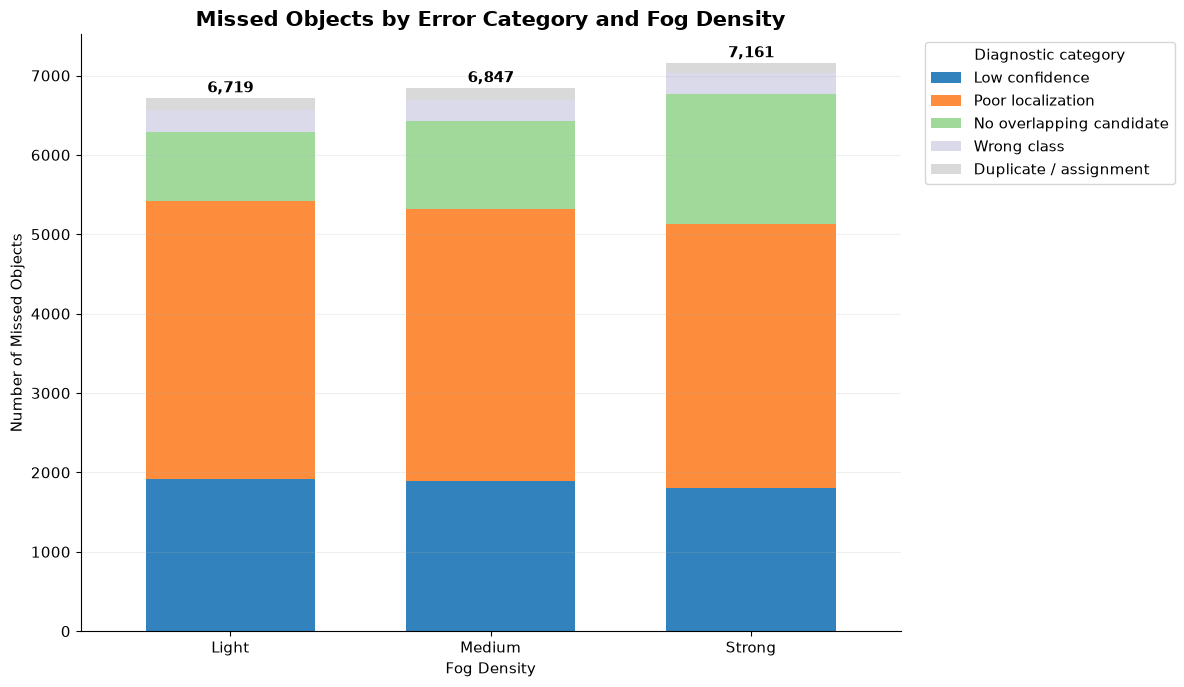

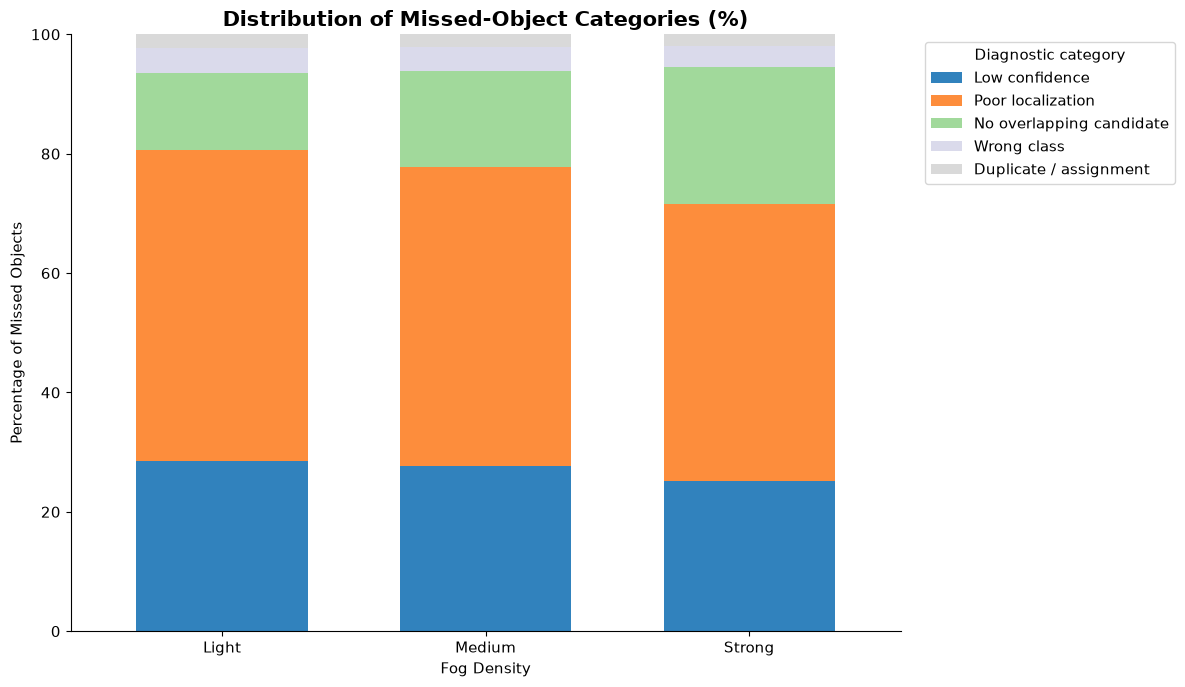

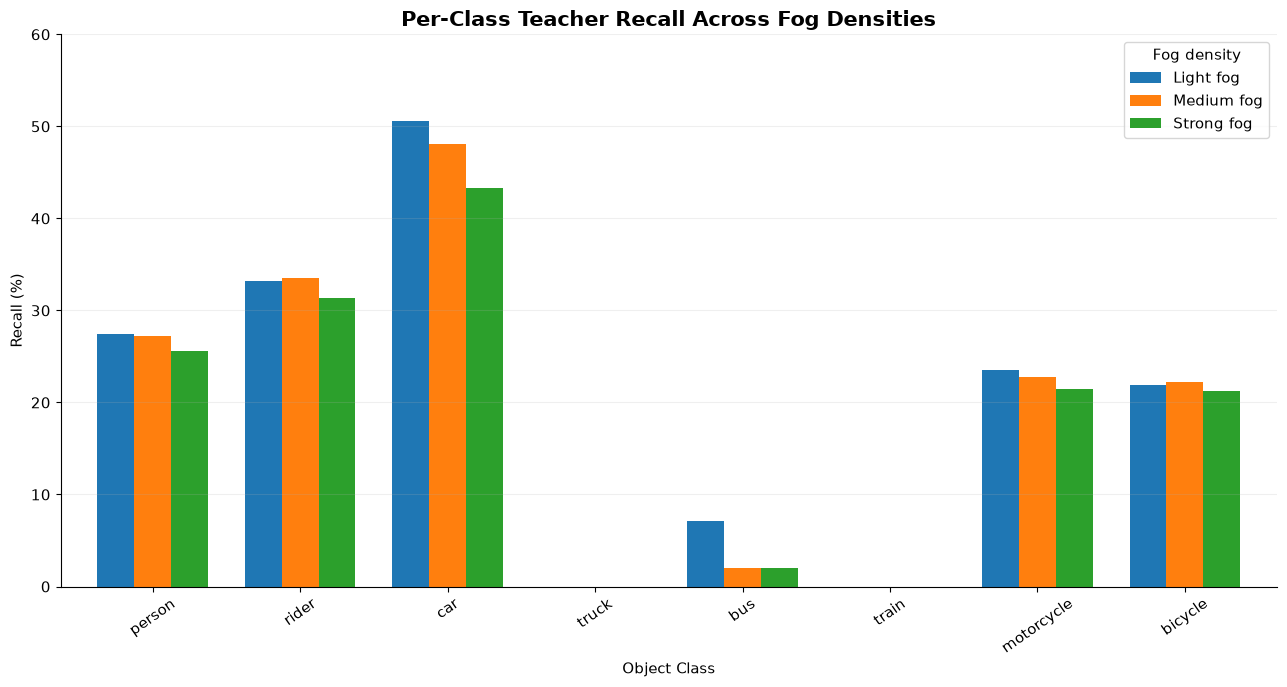

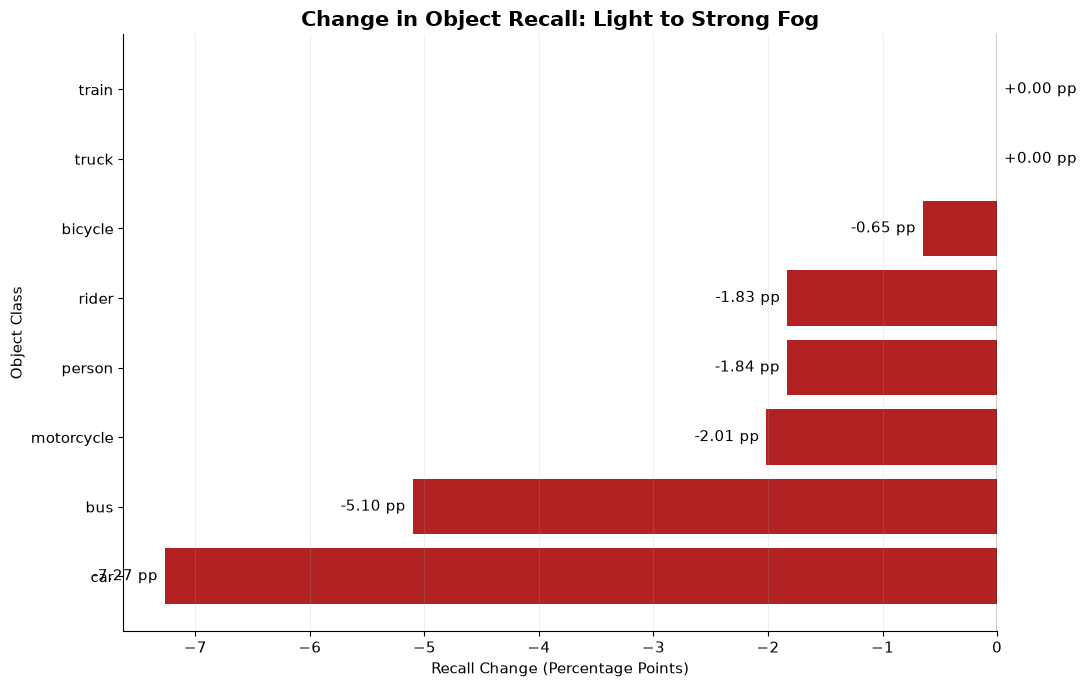

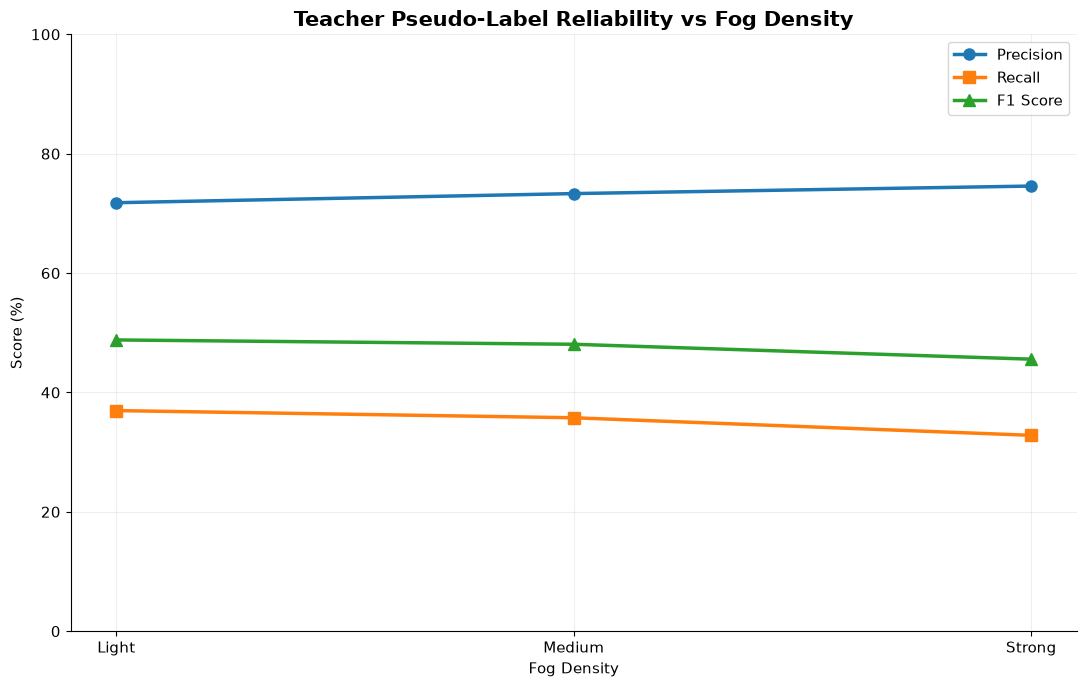

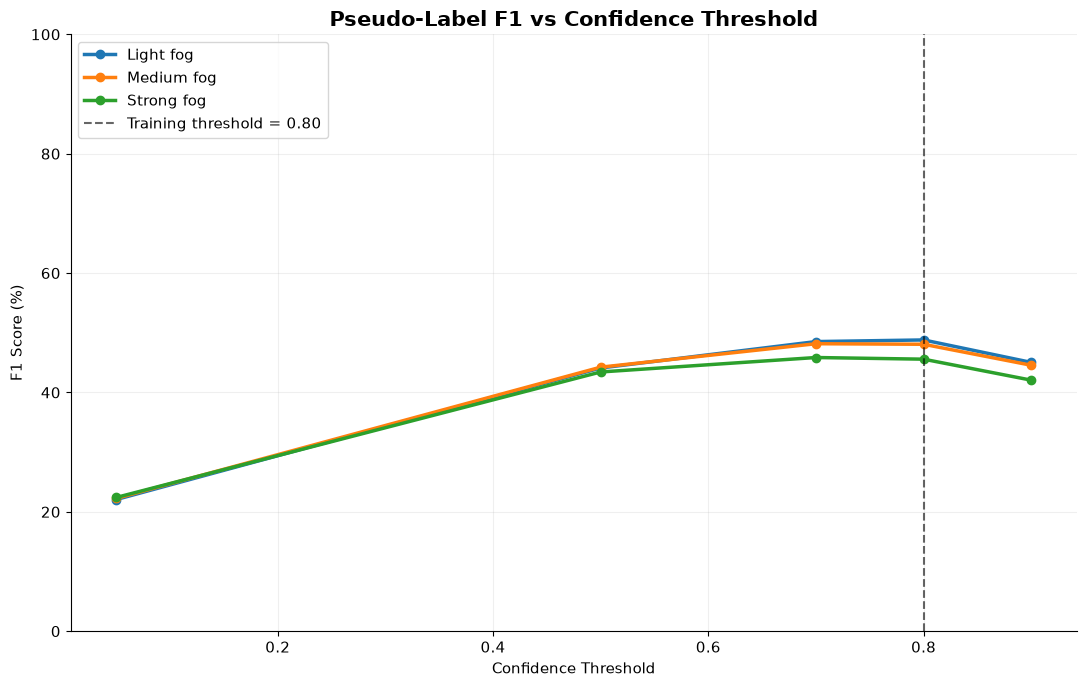


EXPERIMENT 04 — VISUALIZATION COMPLETE

Generated 6 charts in PNG and PDF formats.
Saved at: /workspace/experiments/cityscapes_to_foggy/pseudo_label_analysis/v1/object_analysis_v2/visualizations

MISSED OBJECT SUMMARY


reason,low_confidence_candidate,poor_localization,no_overlapping_candidate,wrong_class_candidate,overlapping_duplicate_or_assignment,total_missed
fog_density,,,,,,
light,1918,3498,868,283,152,6719
medium,1895,3427,1105,270,150,6847
strong,1802,3327,1642,256,134,7161



PER-CLASS RECALL (%)


fog_density,light,medium,strong
class,,,
person,27.47,27.27,25.64
rider,33.15,33.52,31.32
car,50.61,48.10,43.35
truck,0.00,0.00,0.00
bus,7.14,2.04,2.04
train,0.00,0.00,0.00
motorcycle,23.49,22.82,21.48
bicycle,21.94,22.23,21.29



RECALL DEGRADATION (PERCENTAGE POINTS)


class
car          -7.27
bus          -5.10
motorcycle   -2.01
person       -1.84
rider        -1.83
bicycle      -0.65
truck         0.00
train         0.00
dtype: float64

In [4]:

# =====================================================================
# EXPERIMENT 04 — OBJECT-LEVEL RESEARCH VISUALIZATIONS
#
# Reads saved Experiment 04 results.
# No GPU inference or retraining required.
#
# Generates:
# 1. Missed-object reasons by fog density
# 2. Percentage distribution of missed-object reasons
# 3. Per-class recall comparison
# 4. Per-class recall degradation
# 5. Precision / recall / F1 comparison
# 6. Threshold sensitivity under strong fog
#
# All figures saved as PNG and PDF.
# =====================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. PATHS
# ---------------------------------------------------------

BASE = Path(
    "/workspace/experiments/cityscapes_to_foggy/"
    "pseudo_label_analysis/v1"
)

OBJECT_DIR = BASE / "object_analysis_v2"

VIS_DIR = OBJECT_DIR / "visualizations"
VIS_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------
# 2. LOAD RESULTS
# ---------------------------------------------------------

errors = pd.read_csv(
    OBJECT_DIR / "missed_object_reasons.csv"
)

classes = pd.read_csv(
    OBJECT_DIR / "verified_per_class.csv"
)

reliability = pd.read_csv(
    OBJECT_DIR / "verified_reliability.csv"
)

FOG_ORDER = ["light", "medium", "strong"]

REASON_ORDER = [
    "low_confidence_candidate",
    "poor_localization",
    "no_overlapping_candidate",
    "wrong_class_candidate",
    "overlapping_duplicate_or_assignment"
]

REASON_LABELS = {
    "low_confidence_candidate": "Low confidence",
    "poor_localization": "Poor localization",
    "no_overlapping_candidate": "No overlapping candidate",
    "wrong_class_candidate": "Wrong class",
    "overlapping_duplicate_or_assignment": "Duplicate / assignment"
}

CLASS_ORDER = [
    "person", "rider", "car", "truck",
    "bus", "train", "motorcycle", "bicycle"
]

plt.rcParams.update({
    "figure.figsize": (11, 6),
    "font.size": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "savefig.dpi": 250,
})

def save_figure(filename):
    plt.tight_layout()
    plt.savefig(
        VIS_DIR / f"{filename}.png",
        dpi=250,
        bbox_inches="tight"
    )
    plt.savefig(
        VIS_DIR / f"{filename}.pdf",
        bbox_inches="tight"
    )
    plt.show()

# ---------------------------------------------------------
# 3. FIGURE 1 — MISSED-OBJECT REASONS
# ---------------------------------------------------------

reason_counts = (
    errors.groupby(["fog_density", "reason"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=FOG_ORDER, columns=REASON_ORDER, fill_value=0)
)

fig, ax = plt.subplots(figsize=(12, 7))

reason_counts.rename(
    columns=REASON_LABELS
).plot(
    kind="bar",
    stacked=True,
    ax=ax,
    width=0.65,
    colormap="tab20c"
)

ax.set_title(
    "Missed Objects by Error Category and Fog Density",
    fontsize=15,
    weight="bold"
)
ax.set_xlabel("Fog Density")
ax.set_ylabel("Number of Missed Objects")
ax.set_xticklabels(
    ["Light", "Medium", "Strong"],
    rotation=0
)

for i, total in enumerate(reason_counts.sum(axis=1)):
    ax.text(
        i, total + 70,
        f"{total:,}",
        ha="center",
        weight="bold"
    )

ax.legend(
    title="Diagnostic category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
ax.grid(axis="y", alpha=0.2)

save_figure("01_missed_object_reasons")

# ---------------------------------------------------------
# 4. FIGURE 2 — ERROR CATEGORY DISTRIBUTION (%)
# ---------------------------------------------------------

reason_percent = (
    reason_counts.div(
        reason_counts.sum(axis=1),
        axis=0
    ) * 100
)

fig, ax = plt.subplots(figsize=(12, 7))

reason_percent.rename(
    columns=REASON_LABELS
).plot(
    kind="bar",
    stacked=True,
    ax=ax,
    width=0.65,
    colormap="tab20c"
)

ax.set_title(
    "Distribution of Missed-Object Categories (%)",
    fontsize=15,
    weight="bold"
)
ax.set_xlabel("Fog Density")
ax.set_ylabel("Percentage of Missed Objects")
ax.set_xticklabels(
    ["Light", "Medium", "Strong"],
    rotation=0
)
ax.set_ylim(0, 100)

ax.legend(
    title="Diagnostic category",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

save_figure("02_error_distribution_percentage")

# ---------------------------------------------------------
# 5. FIGURE 3 — PER-CLASS RECALL
# ---------------------------------------------------------

class_data = classes[
    np.isclose(classes["threshold"], 0.80)
].copy()

recall = (
    class_data.pivot(
        index="class",
        columns="fog_density",
        values="recall"
    )
    .reindex(index=CLASS_ORDER, columns=FOG_ORDER)
    * 100
)

fig, ax = plt.subplots(figsize=(13, 7))

recall.rename(
    columns={
        "light": "Light fog",
        "medium": "Medium fog",
        "strong": "Strong fog"
    }
).plot(
    kind="bar",
    ax=ax,
    width=0.75
)

ax.set_title(
    "Per-Class Teacher Recall Across Fog Densities",
    fontsize=15,
    weight="bold"
)
ax.set_xlabel("Object Class")
ax.set_ylabel("Recall (%)")
ax.set_ylim(0, max(60, np.nanmax(recall.to_numpy()) + 5))
ax.tick_params(axis="x", rotation=35)
ax.legend(title="Fog density")
ax.grid(axis="y", alpha=0.2)

save_figure("03_per_class_recall")

# ---------------------------------------------------------
# 6. FIGURE 4 — RECALL DEGRADATION
# ---------------------------------------------------------

recall_change = (
    recall["strong"] - recall["light"]
).sort_values()

fig, ax = plt.subplots(figsize=(11, 7))

colors = [
    "firebrick" if value < 0 else "seagreen"
    for value in recall_change
]

bars = ax.barh(
    recall_change.index,
    recall_change.values,
    color=colors
)

ax.axvline(0, color="black", linewidth=1)

ax.set_title(
    "Change in Object Recall: Light to Strong Fog",
    fontsize=15,
    weight="bold"
)
ax.set_xlabel("Recall Change (Percentage Points)")
ax.set_ylabel("Object Class")

for bar, value in zip(bars, recall_change.values):
    ax.annotate(
        f"{value:+.2f} pp",
        xy=(value, bar.get_y() + bar.get_height()/2),
        xytext=(5 if value >= 0 else -5, 0),
        textcoords="offset points",
        va="center",
        ha="left" if value >= 0 else "right"
    )

ax.grid(axis="x", alpha=0.2)

save_figure("04_per_class_recall_degradation")

# ---------------------------------------------------------
# 7. FIGURE 5 — PRECISION, RECALL AND F1
# ---------------------------------------------------------

metrics = reliability[
    np.isclose(reliability["threshold"], 0.80)
].copy()

metrics["fog_density"] = pd.Categorical(
    metrics["fog_density"],
    categories=FOG_ORDER,
    ordered=True
)

metrics = metrics.sort_values("fog_density")

fig, ax = plt.subplots(figsize=(11, 7))

for metric, label, marker in [
    ("precision", "Precision", "o"),
    ("recall", "Recall", "s"),
    ("f1", "F1 Score", "^")
]:
    ax.plot(
        ["Light", "Medium", "Strong"],
        metrics[metric].to_numpy() * 100,
        marker=marker,
        linewidth=2.5,
        markersize=8,
        label=label
    )

ax.set_title(
    "Teacher Pseudo-Label Reliability vs Fog Density",
    fontsize=15,
    weight="bold"
)
ax.set_xlabel("Fog Density")
ax.set_ylabel("Score (%)")
ax.set_ylim(0, 100)
ax.legend()
ax.grid(alpha=0.2)

save_figure("05_precision_recall_f1")

# ---------------------------------------------------------
# 8. FIGURE 6 — CONFIDENCE THRESHOLD SENSITIVITY
# ---------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 7))

for level in FOG_ORDER:

    subset = reliability[
        reliability["fog_density"] == level
    ].sort_values("threshold")

    ax.plot(
        subset["threshold"],
        subset["f1"] * 100,
        marker="o",
        linewidth=2.5,
        label=f"{level.title()} fog"
    )

ax.axvline(
    0.80,
    linestyle="--",
    color="black",
    alpha=0.6,
    label="Training threshold = 0.80"
)

ax.set_title(
    "Pseudo-Label F1 vs Confidence Threshold",
    fontsize=15,
    weight="bold"
)
ax.set_xlabel("Confidence Threshold")
ax.set_ylabel("F1 Score (%)")
ax.set_ylim(0, 100)
ax.legend()
ax.grid(alpha=0.2)

save_figure("06_threshold_sensitivity")

# ---------------------------------------------------------
# 9. EXPORT RESEARCH SUMMARY
# ---------------------------------------------------------

summary = reason_counts.copy()
summary["total_missed"] = summary.sum(axis=1)

summary.to_csv(
    VIS_DIR / "missed_object_summary.csv"
)

recall.to_csv(
    VIS_DIR / "per_class_recall_percent.csv"
)

recall_change.rename(
    "recall_change_pp"
).to_csv(
    VIS_DIR / "per_class_recall_change.csv"
)

print("\n" + "=" * 70)
print("EXPERIMENT 04 — VISUALIZATION COMPLETE")
print("=" * 70)

print("\nGenerated 6 charts in PNG and PDF formats.")
print("Saved at:", VIS_DIR)

print("\nMISSED OBJECT SUMMARY")
display(summary)

print("\nPER-CLASS RECALL (%)")
display(recall.round(2))

print("\nRECALL DEGRADATION (PERCENTAGE POINTS)")
display(recall_change.round(2))
